In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv('/Users/anshjj/Downloads/Campusx_Project/data/Cleaned/property_outlier_treated.csv')

In [4]:
df.head()

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area,area_room_ratio
0,flat,indiabulls centrum park,2.45,8521.0,sector 103,2875.25,Super Built up area 2875(267.1 sq.m.),4.0,4,3.0,11.0,East,Medium Aged,1,1,1,1,0,0,38,2875.0,NaN,NaN,718.812500
1,house,project mianwali colony,2.00,14815.0,mianwali colony,1350.00,Built Up area: 1350 (125.42 sq.m.),5.0,5,2.0,3.0,East,Undefined,0,0,0,0,0,0,0,NaN,1350.0,NaN,270.000000
2,flat,rof ananda,0.38,6919.0,sector 95,549.21,Carpet area: 549.17 (51.02 sq.m.),2.0,2,1.0,4.0,NaN,New,0,0,0,0,0,1,0,NaN,NaN,549.174178,274.605000
3,flat,sare homes,0.68,5238.0,sector 92,1298.21,Carpet area: 1298 (120.59 sq.m.),3.0,3,2.0,11.0,North-West,Medium Aged,1,0,0,0,0,1,100,NaN,NaN,1298.000000,432.736667
4,flat,pyramid urban homes,0.60,8000.0,sector 86,750.00,Carpet area: 750 (69.68 sq.m.),3.0,2,2.0,2.0,East,Under Construction,0,0,0,0,0,1,13,NaN,NaN,750.000000,250.000000


In [5]:
df.isnull().sum()

property_type             0
society                   3
price                     0
price_per_sqft            0
sector                    0
area                      0
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                  84
floorNum                 18
facing                 1034
agePossession             0
Pooja Room                0
Study Room                0
Store Room                0
Servant Room              0
Others                    0
furnishstatus             0
luxury_score              0
super_built_up_area    1759
built_up_area          1966
carpet_area            1772
area_room_ratio           0
dtype: int64

### Built up area

<Axes: xlabel='built_up_area', ylabel='super_built_up_area'>

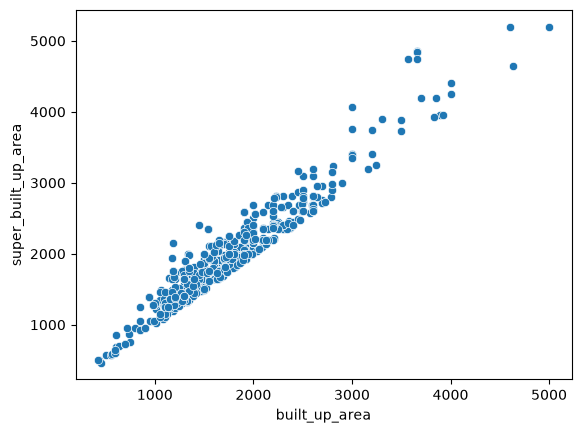

In [7]:
sns.scatterplot(x=df['built_up_area'],y=df['super_built_up_area'])

<Axes: xlabel='built_up_area', ylabel='carpet_area'>

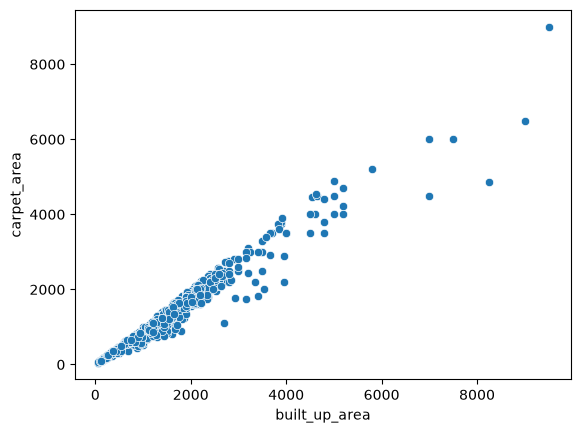

In [8]:
sns.scatterplot(x=df['built_up_area'],y=df['carpet_area'])

In [10]:
df[(df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull())]

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area,area_room_ratio


In [11]:
all_present_df = df[~((df['super_built_up_area'].isnull()) | (df['built_up_area'].isnull()) | (df['carpet_area'].isnull()))]

In [14]:
all_present_df.head()

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area,area_room_ratio
7,flat,tulip white,0.90,6000.0,sector 69,1500.00,Super Built up area 1500(139.35 sq.m.)Built Up...,3.0,2,3.0,1.0,West,Medium Aged,0,0,0,0,0,2,149,1500.0,1326.0,1050.0,500.000000
13,flat,ireo victory valley,3.50,14583.0,sector 67,2400.05,Super Built up area 2698(250.65 sq.m.)Built Up...,3.0,4,3.0,24.0,North-East,Medium Aged,1,0,0,1,0,2,149,2698.0,2490.0,2400.0,800.016667
23,flat,la vida by tata housing,2.35,13352.0,sector 113,1760.04,Super Built up area 2217(205.97 sq.m.)Built Up...,3.0,4,3.0,3.0,West,Medium Aged,0,0,0,1,0,0,174,2217.0,1930.0,1760.0,586.680000
24,flat,bptp mansions park prime,3.00,10853.0,sector 66,2764.21,Super Built up area 2764(256.78 sq.m.)Built Up...,4.0,4,3.0,3.0,North,Medium Aged,1,1,0,1,1,2,174,2764.0,2700.0,2500.0,691.052500
29,flat,dlf new town heights,1.21,6243.0,sector 90,1938.17,Super Built up area 1930(179.3 sq.m.)Built Up ...,3.0,3,3.0,7.0,West,Medium Aged,1,0,0,1,0,1,127,1930.0,1929.0,1928.0,646.056667


In [15]:
super_to_built_up_ratio = (all_present_df['super_built_up_area']/all_present_df['built_up_area']).median()

In [16]:
carpet_to_built_up_ratio = (all_present_df['carpet_area']/all_present_df['built_up_area']).median()

In [17]:
print(super_to_built_up_ratio, carpet_to_built_up_ratio)

1.105263157894737 0.9


In [18]:
# both present built up null
sbc_df = df[~(df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & ~(df['carpet_area'].isnull())]

In [19]:
sbc_df.head()

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area,area_room_ratio
5,flat,eldeco accolade,0.8692,5965.0,sohna road,1457.17,Super Built up area 1457(135.36 sq.m.)Carpet a...,2.0,2,3.0,10.0,NaN,Medium Aged,0,1,0,0,0,1,72,1457.0,NaN,849.0,728.585000
8,flat,trisara our homes,0.3600,5980.0,sohna road,602.01,Super Built up area 602(55.93 sq.m.)Carpet are...,2.0,2,1.0,1.0,NaN,New,0,0,0,0,0,0,45,602.0,NaN,450.0,301.005000
21,flat,eldeco accolade,0.9575,6571.0,sohna road,1457.16,Super Built up area 1457(135.36 sq.m.)Carpet a...,2.0,2,3.0,14.0,East,Medium Aged,0,1,0,0,0,0,151,1457.0,NaN,849.0,728.580000
22,flat,ss the leaf,2.1500,10924.0,sector 85,1968.14,Super Built up area 2812(261.24 sq.m.)Carpet a...,4.0,5,3.0,6.0,South,Medium Aged,0,0,0,1,0,0,156,2812.0,NaN,1968.0,492.035000
25,flat,dlf the ultima,2.3000,14375.0,sector 81,1600.00,Super Built up area 2132(198.07 sq.m.)Carpet a...,3.0,4,3.0,18.0,North-East,Medium Aged,0,0,0,1,0,2,174,2132.0,NaN,1600.0,533.333333


In [20]:
sbc_df['built_up_area'].fillna(round(((sbc_df['super_built_up_area']/1.105) + (sbc_df['carpet_area']/0.9))/2),inplace=True)

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2349/1215074969.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  sbc_df['built_up_area'].fillna(round(((sbc_df['super_built_up_area']/1.105) + (sbc_df['carpet_area']/0.9))/2),inplace=True)
/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2349/1215074969.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#

In [21]:
df.update(sbc_df)

In [22]:
df.isnull().sum()

property_type             0
society                   3
price                     0
price_per_sqft            0
sector                    0
area                      0
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                  84
floorNum                 18
facing                 1034
agePossession             0
Pooja Room                0
Study Room                0
Store Room                0
Servant Room              0
Others                    0
furnishstatus             0
luxury_score              0
super_built_up_area    1759
built_up_area          1545
carpet_area            1772
area_room_ratio           0
dtype: int64

In [23]:
# sb present c is null built up null
sb_df = df[~(df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull())]

In [24]:
sb_df.head()

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area,area_room_ratio
0,flat,indiabulls centrum park,2.45,8521.0,sector 103,2875.25,Super Built up area 2875(267.1 sq.m.),4.0,4,3.0,11.0,East,Medium Aged,1,1,1,1,0,0,38,2875.0,NaN,NaN,718.812500
9,flat,tata primanti,3.25,10545.0,sector 72,3082.03,Super Built up area 3300(306.58 sq.m.),3.0,3,3.0,2.0,South,Old,0,0,0,1,0,1,94,3300.0,NaN,NaN,1027.343333
31,flat,ss the leaf,1.06,6343.0,sector 85,1671.13,Super Built up area 1671(155.24 sq.m.),2.0,2,2.0,12.0,South,Medium Aged,0,0,0,0,0,1,44,1671.0,NaN,NaN,835.565000
37,flat,aipl the peaceful homes,1.60,9584.0,sector 70a,1669.45,Super Built up area 1565(145.39 sq.m.),2.0,2,2.0,22.0,North,Old,0,0,0,0,0,0,86,1565.0,NaN,NaN,834.725000
39,flat,puri emerald bay,1.32,8516.0,sector 104,1550.02,Super Built up area 1550(144 sq.m.),2.0,2,2.0,10.0,North-East,Medium Aged,0,0,0,0,0,0,128,1550.0,NaN,NaN,775.010000


In [25]:
sb_df['built_up_area'].fillna(round(sb_df['super_built_up_area']/1.105),inplace=True)

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2349/1714170073.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  sb_df['built_up_area'].fillna(round(sb_df['super_built_up_area']/1.105),inplace=True)
/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2349/1714170073.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sb_df

In [26]:
df.update(sb_df)

In [27]:
df.isnull().sum()

property_type             0
society                   3
price                     0
price_per_sqft            0
sector                    0
area                      0
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                  84
floorNum                 18
facing                 1034
agePossession             0
Pooja Room                0
Study Room                0
Store Room                0
Servant Room              0
Others                    0
furnishstatus             0
luxury_score              0
super_built_up_area    1759
built_up_area           676
carpet_area            1772
area_room_ratio           0
dtype: int64

In [28]:
# sb null c is present built up null
c_df = df[(df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & ~(df['carpet_area'].isnull())]

In [29]:
c_df.head()

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area,area_room_ratio
2,flat,rof ananda,0.38,6919.0,sector 95,549.21,Carpet area: 549.17 (51.02 sq.m.),2.0,2,1.0,4.0,NaN,New,0,0,0,0,0,1,0,NaN,NaN,549.174178,274.605000
3,flat,sare homes,0.68,5238.0,sector 92,1298.21,Carpet area: 1298 (120.59 sq.m.),3.0,3,2.0,11.0,North-West,Medium Aged,1,0,0,0,0,1,100,NaN,NaN,1298.000000,432.736667
4,flat,pyramid urban homes,0.60,8000.0,sector 86,750.00,Carpet area: 750 (69.68 sq.m.),3.0,2,2.0,2.0,East,Under Construction,0,0,0,0,0,1,13,NaN,NaN,750.000000,250.000000
11,flat,laxmi pareena,0.30,6666.0,sector 99a,450.05,Carpet area: 450 (41.81 sq.m.),2.0,1,NaN,12.0,North,Undefined,0,0,0,0,0,0,0,NaN,NaN,450.000000,225.025000
14,house,anshul,0.85,7727.0,sector 6,1100.00,Carpet area: 1100 (102.19 sq.m.),2.0,2,0.0,4.0,North-East,Undefined,0,0,0,0,0,0,0,NaN,NaN,1100.000000,550.000000


In [30]:
c_df['built_up_area'].fillna(round(c_df['carpet_area']/0.9),inplace=True)

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2349/2136919732.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  c_df['built_up_area'].fillna(round(c_df['carpet_area']/0.9),inplace=True)
/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2349/2136919732.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  c_df['built_up_ar

In [31]:
df.update(c_df)

In [32]:
df.isnull().sum()

property_type             0
society                   3
price                     0
price_per_sqft            0
sector                    0
area                      0
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                  84
floorNum                 18
facing                 1034
agePossession             0
Pooja Room                0
Study Room                0
Store Room                0
Servant Room              0
Others                    0
furnishstatus             0
luxury_score              0
super_built_up_area    1759
built_up_area             0
carpet_area            1772
area_room_ratio           0
dtype: int64

<Axes: xlabel='built_up_area', ylabel='price'>

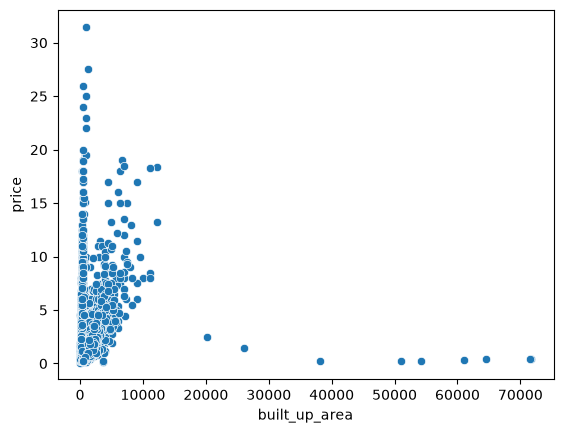

In [34]:
sns.scatterplot(x=df['built_up_area'],y=df['price'])

In [35]:
anamoly_df = df[(df['built_up_area'] < 2000) & (df['price'] > 2.5)][['price','area','built_up_area']]

In [36]:
anamoly_df.sample(5)

,price,area,built_up_area
1465,2.58,2200.05,1991.0
2554,4.25,1836.00,204.0
1628,4.70,2368.00,170.0
1615,3.55,1449.00,161.0
1205,4.45,1265.00,150.0


In [40]:
anamoly_df['built_up_area'] = anamoly_df['area']

In [41]:
df.update(anamoly_df)

<Axes: xlabel='built_up_area', ylabel='price'>

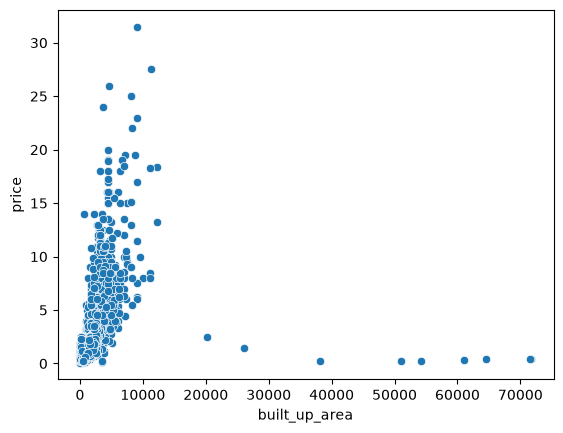

In [42]:
sns.scatterplot(x=df['built_up_area'],y=df['price'])

In [43]:
df.drop(columns=['area','areaWithType','super_built_up_area','carpet_area','area_room_ratio'],inplace=True)

In [44]:
df.head()

,property_type,society,price,price_per_sqft,sector,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,built_up_area
0,flat,indiabulls centrum park,2.45,8521.0,sector 103,4.0,4,3.0,11.0,East,Medium Aged,1,1,1,1,0,0,38,2602.0
1,house,project mianwali colony,2.00,14815.0,mianwali colony,5.0,5,2.0,3.0,East,Undefined,0,0,0,0,0,0,0,1350.0
2,flat,rof ananda,0.38,6919.0,sector 95,2.0,2,1.0,4.0,NaN,New,0,0,0,0,0,1,0,610.0
3,flat,sare homes,0.68,5238.0,sector 92,3.0,3,2.0,11.0,North-West,Medium Aged,1,0,0,0,0,1,100,1442.0
4,flat,pyramid urban homes,0.60,8000.0,sector 86,3.0,2,2.0,2.0,East,Under Construction,0,0,0,0,0,1,13,833.0


In [45]:
df.isnull().sum()

property_type        0
society              3
price                0
price_per_sqft       0
sector               0
bedRoom              0
bathroom             0
balcony             84
floorNum            18
facing            1034
agePossession        0
Pooja Room           0
Study Room           0
Store Room           0
Servant Room         0
Others               0
furnishstatus        0
luxury_score         0
built_up_area        0
dtype: int64

### floorNum

In [46]:
df[df['floorNum'].isnull()]

,property_type,society,price,price_per_sqft,sector,bedRoom,bathroom,balcony,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,built_up_area
32,house,independent,1.50,10288.0,ashok vihar,3.0,3,0.0,NaN,NaN,Very Old,0,0,0,0,0,1,0,210.0
300,house,independent,0.65,11111.0,laxman vihar,4.0,2,2.0,NaN,NaN,Old,0,0,0,0,0,0,0,65.0
361,house,independent,4.12,8889.0,laxman vihar phase 2,2.0,1,3.0,NaN,NaN,Old,0,0,0,0,0,1,0,4635.0
1121,house,independent,1.10,8148.0,bhawani enclave,2.0,2,1.0,NaN,NaN,Very Old,0,0,0,0,1,0,0,150.0
1229,house,ansal sushant lok plots,3.30,26570.0,sushant lok phase 1,1.0,1,0.0,NaN,NaN,Under Construction,0,0,0,0,0,1,0,1242.0
1290,house,independent,2.50,5472.0,new palam vihar phase 2,3.0,2,1.0,NaN,NaN,Very Old,0,0,0,0,0,1,8,4000.0
1460,house,jacob pura,0.35,9722.0,jacobpura,2.0,1,0.0,NaN,NaN,Very Old,0,0,0,0,0,1,0,360.0
1612,house,dlf new town heights,2.47,7719.0,sector 86,4.0,4,3.0,NaN,West,Old,1,0,0,1,0,2,130,2800.0
1837,house,vipul tatvam villa,8.50,26235.0,sector 48,4.0,4,2.0,NaN,East,Old,1,0,1,1,0,0,88,3240.0
2208,house,independent,6.50,15046.0,new colony,3.0,2,3.0,NaN,NaN,Very Old,0,0,0,0,0,1,9,4320.0


In [47]:
df[df['property_type'] == 'house']['floorNum'].median()

2.0

In [48]:
df['floorNum'].fillna(2.0,inplace=True)

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2349/15612474.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['floorNum'].fillna(2.0,inplace=True)


In [49]:
df.isnull().sum()

property_type        0
society              3
price                0
price_per_sqft       0
sector               0
bedRoom              0
bathroom             0
balcony             84
floorNum             0
facing            1034
agePossession        0
Pooja Room           0
Study Room           0
Store Room           0
Servant Room         0
Others               0
furnishstatus        0
luxury_score         0
built_up_area        0
dtype: int64

In [50]:
1011/df.shape[0]

0.2788196359624931

### facing

<Axes: ylabel='count'>

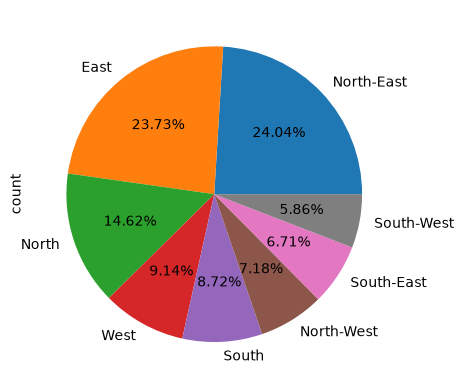

In [51]:
df['facing'].value_counts().plot(kind='pie',autopct='%0.2f%%')

In [52]:
df.drop(columns=['facing'],inplace=True)

In [53]:
df.sample(5)

,property_type,society,price,price_per_sqft,sector,bedRoom,bathroom,balcony,floorNum,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,built_up_area
1473,house,spaze privy,3.10,8486.0,sector 72,5.0,5,3.0,21.0,Medium Aged,0,0,0,0,0,0,0,3653.0
1221,flat,shree vardhman victoria,1.65,8461.0,sector 70,3.0,4,3.0,12.0,Medium Aged,0,0,1,1,0,0,56,1765.0
1132,flat,corona gracieux,0.75,5660.0,sector 76,2.0,2,3.0,13.0,Medium Aged,0,0,0,0,0,2,0,1199.0
1633,flat,vatika gurgaon,1.12,6455.0,sector 83,3.0,3,2.0,4.0,Medium Aged,1,1,1,1,0,2,165,1200.0
1139,house,independent,0.35,7778.0,vishnu garden,2.0,2,1.0,2.0,Undefined,0,0,0,0,0,1,0,556.0


In [54]:
df.isnull().sum()

property_type      0
society            3
price              0
price_per_sqft     0
sector             0
bedRoom            0
bathroom           0
balcony           84
floorNum           0
agePossession      0
Pooja Room         0
Study Room         0
Store Room         0
Servant Room       0
Others             0
furnishstatus      0
luxury_score       0
built_up_area      0
dtype: int64

In [60]:
df.drop(index=df[df['society'].isnull()].index,inplace=True)

In [61]:
df.isnull().sum()

property_type      0
society            0
price              0
price_per_sqft     0
sector             0
bedRoom            0
bathroom           0
balcony           83
floorNum           0
agePossession      0
Pooja Room         0
Study Room         0
Store Room         0
Servant Room       0
Others             0
furnishstatus      0
luxury_score       0
built_up_area      0
dtype: int64

### agePossession

In [62]:
df['agePossession'].value_counts()

agePossession
Medium Aged           1623
Old                    561
New                    472
Under Construction     348
Very Old               318
Undefined              300
Name: count, dtype: int64

In [63]:
df[df['agePossession'] == 'Undefined']

,property_type,society,price,price_per_sqft,sector,bedRoom,bathroom,balcony,floorNum,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,built_up_area
1,house,project mianwali colony,2.00,14815.0,mianwali colony,5.0,5,2.0,3.0,Undefined,0,0,0,0,0,0,0,1350.0
11,flat,laxmi pareena,0.30,6666.0,sector 99a,2.0,1,NaN,12.0,Undefined,0,0,0,0,0,0,0,500.0
14,house,anshul,0.85,7727.0,sector 6,2.0,2,0.0,4.0,Undefined,0,0,0,0,0,0,0,1222.0
16,house,independent,4.75,10556.0,sector 1,6.0,7,0.0,4.0,Undefined,0,0,0,0,0,0,0,4500.0
38,house,independent,4.50,13889.0,dlf phase 4,4.0,4,0.0,4.0,Undefined,0,0,0,0,0,0,0,3240.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3588,house,independent,1.20,4444.0,sector 11,7.0,3,0.0,3.0,Undefined,0,0,0,0,0,1,0,300.0
3592,flat,signature global park,0.87,7190.0,sohna road,3.0,2,3.0,4.0,Undefined,0,0,0,0,0,0,58,1210.0
3601,flat,m,1.83,13969.0,sector 113,2.0,2,NaN,7.0,Undefined,0,0,0,0,0,1,0,1310.0
3614,flat,godrej nature plus,1.75,8768.0,sector-33 sohna road,3.0,3,NaN,2.0,Undefined,0,0,0,0,0,1,56,1996.0


In [64]:
def mode_based_imputation(row):
    if row['agePossession'] == 'Undefined':
        mode_value = df[(df['sector'] == row['sector']) & (df['property_type'] == row['property_type'])]['agePossession'].mode()
        # If mode_value is empty (no mode found), return NaN, otherwise return the mode
        if not mode_value.empty:
            return mode_value.iloc[0] 
        else:
            return np.nan
    else:
        return row['agePossession']

In [65]:
df['agePossession'] = df.apply(mode_based_imputation,axis=1)

In [66]:
df['agePossession'].value_counts()

agePossession
Medium Aged           1762
Old                    599
New                    483
Under Construction     371
Very Old               335
Undefined               72
Name: count, dtype: int64

In [67]:
def mode_based_imputation2(row):
    if row['agePossession'] == 'Undefined':
        mode_value = df[(df['sector'] == row['sector'])]['agePossession'].mode()
        # If mode_value is empty (no mode found), return NaN, otherwise return the mode
        if not mode_value.empty:
            return mode_value.iloc[0] 
        else:
            return np.nan
    else:
        return row['agePossession']

In [68]:
df['agePossession'] = df.apply(mode_based_imputation2,axis=1)

In [69]:
df['agePossession'].value_counts()

agePossession
Medium Aged           1773
Old                    604
New                    484
Under Construction     373
Very Old               338
Undefined               50
Name: count, dtype: int64

In [70]:
def mode_based_imputation3(row):
    if row['agePossession'] == 'Undefined':
        mode_value = df[(df['property_type'] == row['property_type'])]['agePossession'].mode()
        # If mode_value is empty (no mode found), return NaN, otherwise return the mode
        if not mode_value.empty:
            return mode_value.iloc[0] 
        else:
            return np.nan
    else:
        return row['agePossession']

In [71]:
df['agePossession'] = df.apply(mode_based_imputation3,axis=1)

In [72]:
df['agePossession'].value_counts()

agePossession
Medium Aged           1777
Old                    650
New                    484
Under Construction     373
Very Old               338
Name: count, dtype: int64

In [73]:
df.isnull().sum()

property_type      0
society            0
price              0
price_per_sqft     0
sector             0
bedRoom            0
bathroom           0
balcony           83
floorNum           0
agePossession      0
Pooja Room         0
Study Room         0
Store Room         0
Servant Room       0
Others             0
furnishstatus      0
luxury_score       0
built_up_area      0
dtype: int64

In [76]:
df[df['balcony'].isnull()]['property_type'].value_counts()

property_type
flat    83
Name: count, dtype: int64

In [78]:
df['balcony'].fillna(df[df['property_type']=='flat']['balcony'].median(),inplace=True)

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_2349/3096816347.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['balcony'].fillna(df[df['property_type']=='flat']['balcony'].median(),inplace=True)


In [79]:
df.to_csv('/Users/anshjj/Downloads/Campusx_Project/data/Cleaned/gurgaon_properties_missing_value_imputation.csv',index=False)

In [80]:
df.shape

(3622, 18)